# Comparativa de rendimiento: NumPy (CPU) vs PyTorch (GPU)
Versión actualizada con validación de resultados, manejo de NaNs, y mejoras gráficas.

In [ ]:
import numpy as np
import torch
import time
import matplotlib.pyplot as plt

import utils_numpy as np_utils
import utils_torch as torch_utils

np.random.seed(42)
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo de ejecución: {device.upper()}")

Dispositivo de ejecución: CUDA


In [2]:
sizes = [(100,100), (500,500), (1000,1000), (5000,5000), (10000,10000)]
functions = ['check_symmetric', 'make_symmetric', 'check_square', 'split', 'concat']
results = {f: {'numpy': [], 'torch': []} for f in functions}

In [3]:
for size in sizes:
    print(f"\n{'='*60}\nTamaño: {size}\n{'='*60}")

    np_data = np.random.rand(*size).astype(np.float32)
    torch_data = torch.from_numpy(np_data).to(device)
    np_data_split = np.array_split(np_data, 2)
    torch_data_split = torch.chunk(torch_data, 2)

    for func in functions:
        try:
            if func == 'split':
                sections = size[0] // 2
                np_args = (np_data, [sections])
                torch_args = (torch_data, torch.tensor([sections], device=device))
            elif func == 'concat':
                np_args = (np_data_split,)
                torch_args = (torch_data_split,)
            else:
                np_args = (np_data,)
                torch_args = (torch_data,)

            _ = getattr(np_utils, func)(*np_args)
            _ = getattr(torch_utils, func)(*torch_args)
            if device == 'cuda':
                torch.cuda.synchronize()

            def timed_np():
                times = []
                for _ in range(30):
                    start = time.perf_counter()
                    _ = getattr(np_utils, func)(*np_args)
                    times.append(time.perf_counter() - start)
                return np.median(times)

            def timed_torch():
                times = []
                for _ in range(30):
                    start = time.perf_counter()
                    _ = getattr(torch_utils, func)(*torch_args)
                    if device == 'cuda':
                        torch.cuda.synchronize()
                    times.append(time.perf_counter() - start)
                return np.median(times)

            np_time = timed_np()
            torch_time = timed_torch()
            results[func]['numpy'].append(np_time)
            results[func]['torch'].append(torch_time)

            speedup = np_time / torch_time if torch_time > 0 else float('nan')
            print(f"{func.upper()}\nNumPy: {np_time:.6f} s | Torch: {torch_time:.6f} s | Speedup: {speedup:.2f}x")

        except Exception as e:
            print(f"Error en {func}: {str(e)}")
            results[func]['numpy'].append(np.nan)
            results[func]['torch'].append(np.nan)


Tamaño: (100, 100)
CHECK_SYMMETRIC
NumPy: 0.000034 s | Torch: 0.000206 s | Speedup: 0.17x
MAKE_SYMMETRIC
NumPy: 0.000025 s | Torch: 0.000031 s | Speedup: 0.80x
CHECK_SQUARE
NumPy: 0.000000 s | Torch: 0.000003 s | Speedup: 0.06x
SPLIT
NumPy: 0.000002 s | Torch: 0.000025 s | Speedup: 0.08x
CONCAT
NumPy: 0.000002 s | Torch: 0.000013 s | Speedup: 0.17x

Tamaño: (500, 500)
CHECK_SYMMETRIC
NumPy: 0.000585 s | Torch: 0.000147 s | Speedup: 3.97x
MAKE_SYMMETRIC
NumPy: 0.000393 s | Torch: 0.000036 s | Speedup: 11.03x
CHECK_SQUARE
NumPy: 0.000000 s | Torch: 0.000003 s | Speedup: 0.03x
SPLIT
NumPy: 0.000002 s | Torch: 0.000025 s | Speedup: 0.08x
CONCAT
NumPy: 0.000023 s | Torch: 0.000014 s | Speedup: 1.69x

Tamaño: (1000, 1000)
CHECK_SYMMETRIC
NumPy: 0.007403 s | Torch: 0.000308 s | Speedup: 24.04x
MAKE_SYMMETRIC
NumPy: 0.003864 s | Torch: 0.000092 s | Speedup: 41.84x
CHECK_SQUARE
NumPy: 0.000000 s | Torch: 0.000003 s | Speedup: 0.03x
SPLIT
NumPy: 0.000002 s | Torch: 0.000025 s | Speedup: 0.08x
C

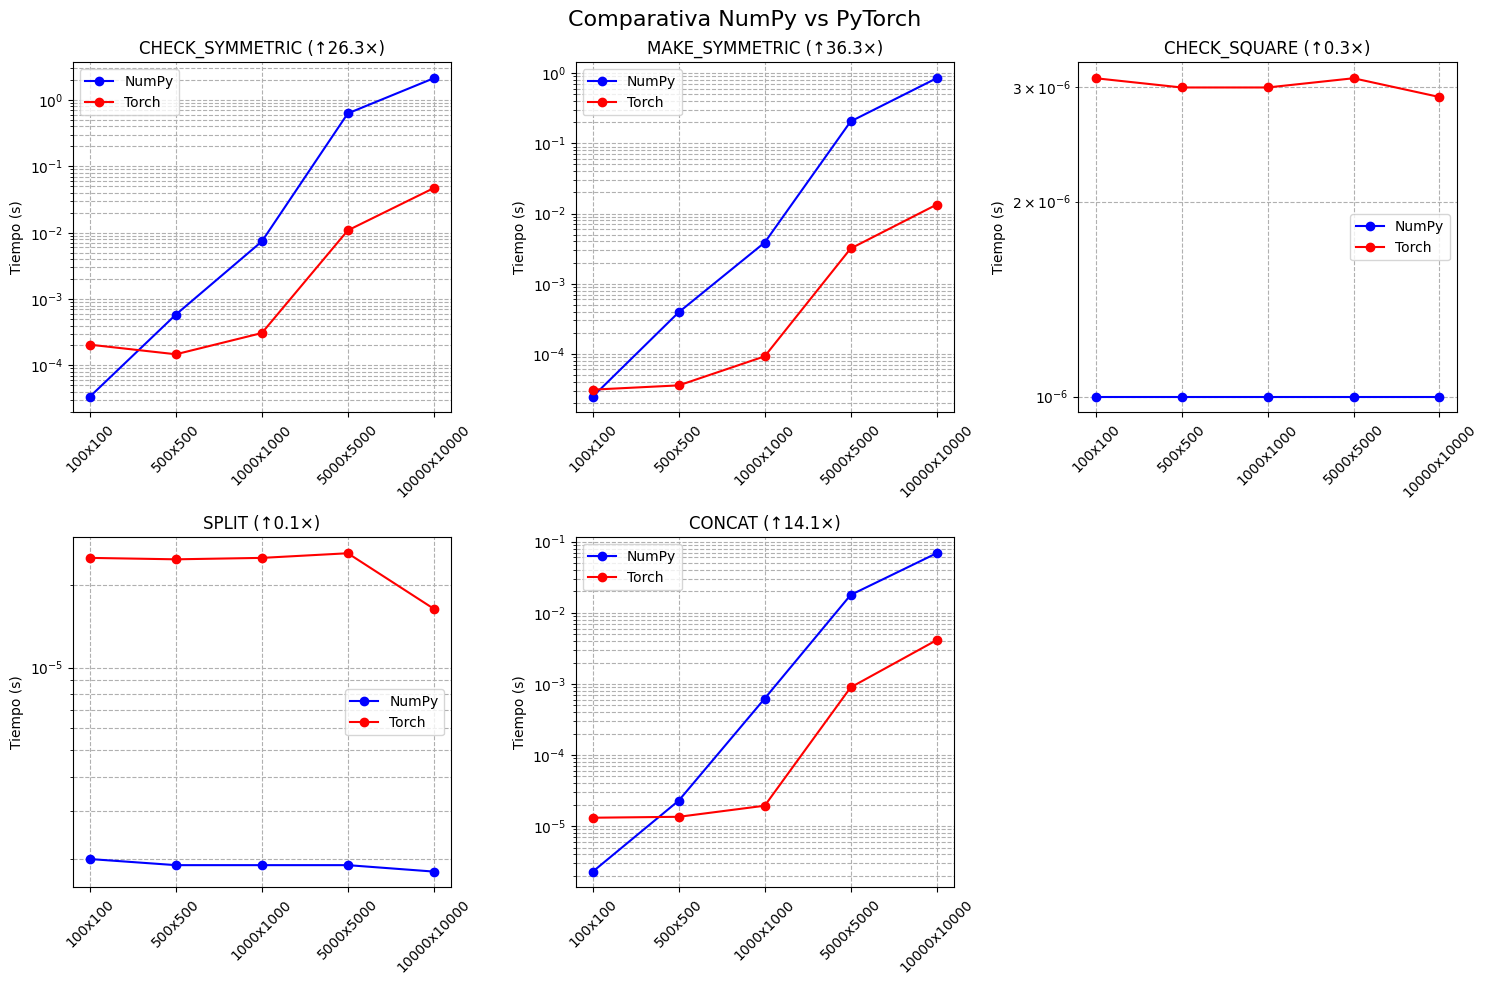

In [4]:
plt.figure(figsize=(15, 10))
plt.suptitle('Comparativa NumPy vs PyTorch', fontsize=16)

for i, func in enumerate(functions, 1):
    plt.subplot(2, 3, i)
    x = range(len(sizes))
    labels = [f"{s[0]}x{s[1]}" for s in sizes]

    numpy_vals = results[func]['numpy'][:len(sizes)]
    torch_vals = results[func]['torch'][:len(sizes)]

    if not any(np.isfinite(numpy_vals)) or not any(np.isfinite(torch_vals)):
        print(f"[ERROR] '{func}' no tiene datos válidos. Saltando.")
        continue

    numpy_vals = [max(v, 1e-6) if np.isfinite(v) else 1e-6 for v in numpy_vals]
    torch_vals = [max(v, 1e-6) if np.isfinite(v) else 1e-6 for v in torch_vals]

    plt.plot(x, numpy_vals, 'bo-', label='NumPy')
    plt.plot(x, torch_vals, 'ro-', label='Torch')

    speedups = [n / t for n, t in zip(numpy_vals, torch_vals) if t > 0]
    avg_speedup = np.mean(speedups) if speedups else 0
    plt.title(f"{func.upper()} (↑{avg_speedup:.1f}×)")

    plt.xticks(x, labels, rotation=45)
    plt.ylabel('Tiempo (s)')
    if all(val > 0 for val in numpy_vals) and all(val > 0 for val in torch_vals):
        plt.yscale('log')
    else:
        print(f"[AVISO] '{func}' contiene ceros o NaNs, se usará escala lineal.")
    plt.grid(True, which="both", ls="--")
    plt.legend()

plt.tight_layout()
plt.show()